# Analyzing the data

## Importing libraries and the data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# master sheet
url = 'https://drive.google.com/file/d/17gNEvy4eMzcEHMGY_SRgRFij0YWo_5kE/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
survey_master = pd.read_csv(path)

# cleaned main sheets
url = 'https://drive.google.com/file/d/1vPJs9TsoYSyRkGD80HdFdZiHm2n_T-iu/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
quality_life_cl = pd.read_csv(path)

url = 'https://drive.google.com/file/d/1pjRLP41uhhsggcZS82txbkxN5W1SYypo/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
green_space_cl = pd.read_csv(path)

# individual survey results
# main
url = 'https://drive.google.com/file/d/1jrW00Y65jXyfjyShtAVdxiXh13ngJLds/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
city_satisfaction = pd.read_csv(path)

url = 'https://drive.google.com/file/d/1VKZsmrJfnbyhcsTB_ED4Md8L4IpN-uc7/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
green_space_satisfaction = pd.read_csv(path)

# side
url = 'https://drive.google.com/file/d/1g_F056IwJLuUh2CPQ4z5ezUioiw9Tumm/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
air_quality_satisfaction = pd.read_csv(path)

url = 'https://drive.google.com/file/d/1YeClgw05XscyOAzO1xwO3P-dFrmEYBQw/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+url.split('/')[-2]
city_health = pd.read_csv(path)


## Statistic of the data

In [4]:
survey_master

,city,country,city_strongly_agree,city_somewhat_agree,green_very_satisfied,green_rather_satisfied,total_green_infrastructure,urban_green_space,urban_tree_cover
0,Vienna,Austria,73.9,19.8,58.4,31.1,44.0,10.0,34.0
1,Brussels,Belgium,37.7,49.7,31.8,52.2,42.0,12.0,37.0
2,Sofia,Bulgaria,34.2,48.2,12.7,51.0,46.0,4.0,37.0
3,Nicosia,Cyprus,38.7,46.4,19.6,34.1,21.0,2.0,4.0
4,Prague,Czechia,40.3,52.0,30.5,48.1,36.0,9.0,29.0
5,Berlin,Germany,55.8,34.7,37.2,49.6,51.0,9.0,44.0
6,Copenhagen,Denmark,77.8,20.1,50.7,39.2,30.0,10.0,16.0
7,Tallinn,Estonia,54.9,36.7,35.9,49.1,50.0,10.0,43.0
8,Athens,Greece,15.0,49.1,6.7,22.3,17.0,15.0,11.0
9,Madrid,Spain,40.8,42.8,24.7,42.6,53.0,9.0,39.0


In [5]:
survey_master.describe()

,city_strongly_agree,city_somewhat_agree,green_very_satisfied,green_rather_satisfied,total_green_infrastructure,urban_green_space,urban_tree_cover
count,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000
mean,51.234483,37.220690,32.210345,43.086207,41.517241,6.793103,30.379310
std,18.621211,12.825627,14.245609,8.629672,15.141289,4.716077,15.552707
min,15.000000,14.400000,6.700000,22.300000,17.000000,0.000000,4.000000
25%,38.700000,26.400000,19.600000,38.100000,31.000000,3.000000,20.000000
50%,46.900000,36.800000,32.500000,45.700000,42.000000,6.000000,34.000000
75%,67.300000,48.200000,43.100000,49.600000,48.000000,10.000000,40.000000
max,82.700000,63.900000,58.400000,55.400000,77.000000,19.000000,72.000000


In [6]:
survey_master.info()

<class 'pandas.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   city                        29 non-null     str    
 1   country                     29 non-null     str    
 2   city_strongly_agree         29 non-null     float64
 3   city_somewhat_agree         29 non-null     float64
 4   green_very_satisfied        29 non-null     float64
 5   green_rather_satisfied      29 non-null     float64
 6   total_green_infrastructure  29 non-null     float64
 7   urban_green_space           29 non-null     float64
 8   urban_tree_cover            29 non-null     float64
dtypes: float64(7), str(2)
memory usage: 2.6 KB


### Creating a scatter plot

In [7]:
survey_master_pl = survey_master.copy()

In [8]:
# adding up the positives
survey_master_pl["city_satisfaction"] = (survey_master_pl["city_strongly_agree"] + survey_master_pl["city_somewhat_agree"])
survey_master_pl["green_space_satisfaction"] = (survey_master_pl["green_very_satisfied"] + survey_master_pl["green_rather_satisfied"])

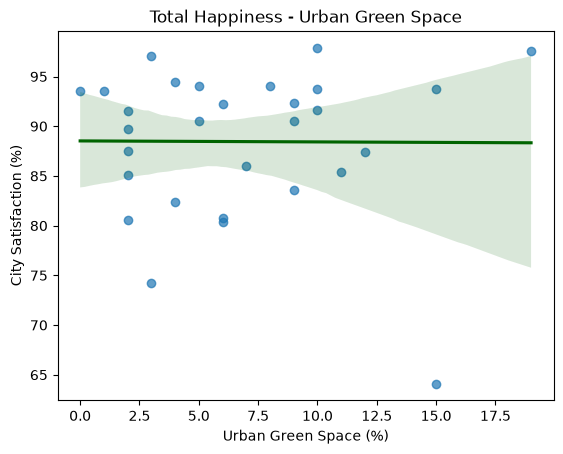

In [9]:
sns.regplot(data=survey_master_pl,
            x="urban_green_space",
            y="city_satisfaction",
            scatter_kws={"alpha": 0.7},
            line_kws={"color": "darkgreen"}
            )

plt.title("Total Happiness - Urban Green Space")
plt.xlabel("Urban Green Space (%)")
plt.ylabel("City Satisfaction (%)")
plt.show()

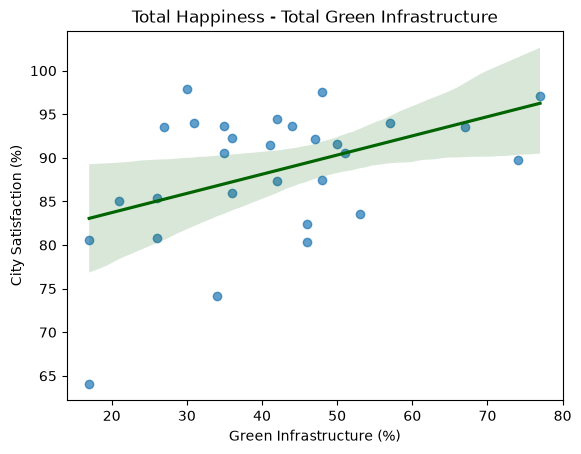

In [10]:
sns.regplot(data=survey_master_pl,
            x="total_green_infrastructure",
            y="city_satisfaction",
            scatter_kws={"alpha": 0.7},
            line_kws={"color": "darkgreen"}
            )

plt.title("Total Happiness - Total Green Infrastructure")
plt.xlabel("Green Infrastructure (%)")
plt.ylabel("City Satisfaction (%)")
plt.show()

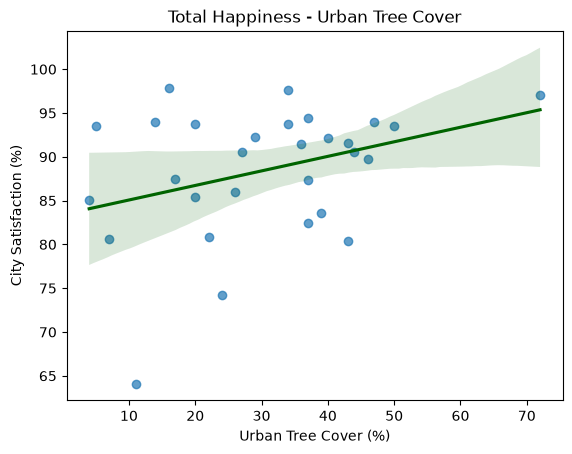

In [11]:
sns.regplot(data=survey_master_pl,
            x="urban_tree_cover",
            y="city_satisfaction",
            scatter_kws={"alpha": 0.7},
            line_kws={"color": "darkgreen"}
            )

plt.title("Total Happiness - Urban Tree Cover")
plt.xlabel("Urban Tree Cover (%)")
plt.ylabel("City Satisfaction (%)")
plt.show()

While Urban Tree Cover and Total Green Infrastructure seem to affect a city's happiness, the percent of urban green space is less of a key factor to it.The analysis explores the association between urban green space coverage, total green infrastructure, and tree cover, and residents’ satisfaction with living in their city. These relationships may vary depending on the measure of urban greenery used

### Are people more like to strongly agree to be satisfied living in their city, in correlation to higher green space coverage?

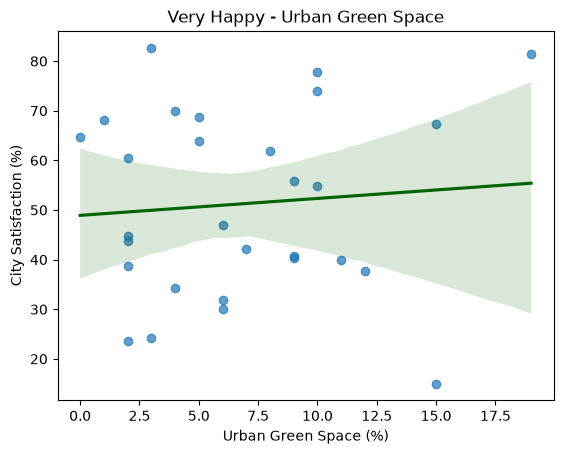

In [12]:
sns.regplot(data=survey_master_pl,
            x="urban_green_space",
            y="city_strongly_agree",
            scatter_kws={"alpha": 0.7},
            line_kws={"color": "darkgreen"}
            )

plt.title("Very Happy - Urban Green Space")
plt.xlabel("Urban Green Space (%)")
plt.ylabel("City Satisfaction (%)")
plt.show()

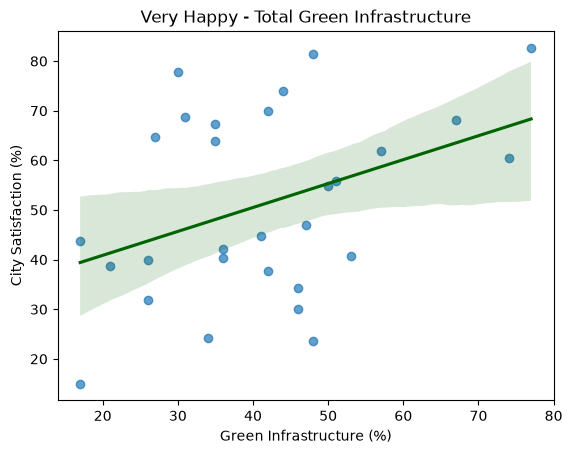

In [13]:
sns.regplot(data=survey_master_pl,
            x="total_green_infrastructure",
            y="city_strongly_agree",
            scatter_kws={"alpha": 0.7},
            line_kws={"color": "darkgreen"}
            )

plt.title("Very Happy - Total Green Infrastructure")
plt.xlabel("Green Infrastructure (%)")
plt.ylabel("City Satisfaction (%)")
plt.show()

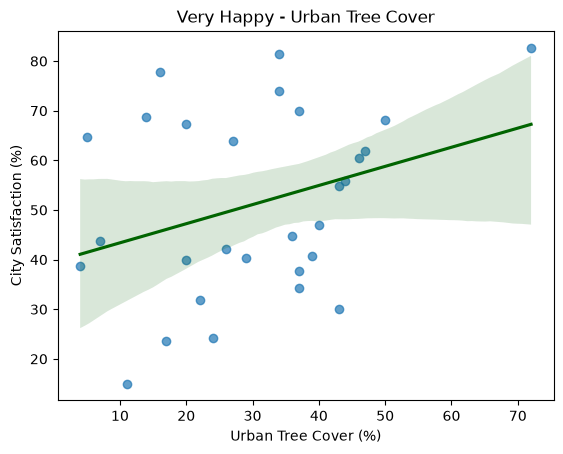

In [14]:
sns.regplot(data=survey_master_pl,
            x="urban_tree_cover",
            y="city_strongly_agree",
            scatter_kws={"alpha": 0.7},
            line_kws={"color": "darkgreen"}
            )

plt.title("Very Happy - Urban Tree Cover")
plt.xlabel("Urban Tree Cover (%)")
plt.ylabel("City Satisfaction (%)")
plt.show()

Get the mean to split the cities into quadrants

In [15]:
# Get the mean of satisfaction and green space cover
satisfaction_mean = survey_master_pl["city_satisfaction"].mean()
green_mean = survey_master_pl["total_green_infrastructure"].mean()


In [16]:
survey_master_pl["quadrant"] = "Less Green & Less Satisfied"

survey_master_pl.loc[(survey_master_pl["total_green_infrastructure"] >= green_mean) & (survey_master_pl["city_satisfaction"] >= satisfaction_mean), "quadrant"] = "Greener & More Satisfied"

survey_master_pl.loc[(survey_master_pl["total_green_infrastructure"] >= green_mean) & (survey_master_pl["city_satisfaction"] < satisfaction_mean), "quadrant"] = "Greener & Less Satisfied"

survey_master_pl.loc[(survey_master_pl["total_green_infrastructure"] < green_mean) & (survey_master_pl["city_satisfaction"] >= satisfaction_mean), "quadrant"] = "Less Green & More Satisfied"

survey_master_pl[["city","country","quadrant"]]

,city,country,quadrant
0,Vienna,Austria,Greener & More Satisfied
1,Brussels,Belgium,Greener & Less Satisfied
2,Sofia,Bulgaria,Greener & Less Satisfied
3,Nicosia,Cyprus,Less Green & Less Satisfied
4,Prague,Czechia,Less Green & More Satisfied
5,Berlin,Germany,Greener & More Satisfied
6,Copenhagen,Denmark,Less Green & More Satisfied
7,Tallinn,Estonia,Greener & More Satisfied
8,Athens,Greece,Less Green & Less Satisfied
9,Madrid,Spain,Greener & Less Satisfied


In [17]:
survey_master_pl["quadrant"].value_counts()

quadrant
Greener & More Satisfied       10
Less Green & Less Satisfied     7
Less Green & More Satisfied     7
Greener & Less Satisfied        5
Name: count, dtype: int64

- Fifteen cities fall into the two quadrants where green space coverage and satisfaction are aligned: Eight are greener and more satisfied, and seven are less green and less satisfied

- Fourteen cities fall into the two quadrants where green space coverage and satisfaction are not aligned: Nine are less green but more satisfied and five are greener but less satisfied

In [18]:
print(survey_master_pl.sort_values("urban_green_space", ascending=False)[["city", "urban_green_space", "city_satisfaction"]].head(5))

         city  urban_green_space  city_satisfaction
25  Stockholm               19.0               97.6
13     Dublin               15.0               93.7
8      Athens               15.0               64.1
1    Brussels               12.0               87.4
10      Paris               11.0               85.4


In [19]:
print(survey_master_pl.sort_values("city_satisfaction")[["city", "urban_green_space", "city_satisfaction"]].head(5))

         city  urban_green_space  city_satisfaction
8      Athens               15.0               64.1
15       Rome                3.0               74.2
18       Riga                6.0               80.4
19   Valletta                2.0               80.6
24  Bucharest                6.0               80.8


Correlation Calculation

In [20]:
corr_total_green = survey_master_pl[["total_green_infrastructure", "city_satisfaction", "green_space_satisfaction"]].corr()
print(corr_total_green)

                            total_green_infrastructure  city_satisfaction  \
total_green_infrastructure                    1.000000           0.443706   
city_satisfaction                             0.443706           1.000000   
green_space_satisfaction                      0.552783           0.802679   

                            green_space_satisfaction  
total_green_infrastructure                  0.552783  
city_satisfaction                           0.802679  
green_space_satisfaction                    1.000000  


In [21]:
corr_urban_green = survey_master_pl[["urban_green_space", "city_satisfaction", "green_space_satisfaction"]].corr()
print(corr_urban_green)

                          urban_green_space  city_satisfaction  \
urban_green_space                  1.000000          -0.006222   
city_satisfaction                 -0.006222           1.000000   
green_space_satisfaction           0.187225           0.802679   

                          green_space_satisfaction  
urban_green_space                         0.187225  
city_satisfaction                         0.802679  
green_space_satisfaction                  1.000000  


In [22]:
corr_urban_tree = survey_master_pl[["urban_tree_cover", "city_satisfaction", "green_space_satisfaction"]].corr()
print(corr_urban_tree)

                          urban_tree_cover  city_satisfaction  \
urban_tree_cover                  1.000000           0.344081   
city_satisfaction                 0.344081           1.000000   
green_space_satisfaction          0.526720           0.802679   

                          green_space_satisfaction  
urban_tree_cover                          0.526720  
city_satisfaction                         0.802679  
green_space_satisfaction                  1.000000  


## Exporting the table for work in Tableau

Rearanging the column order

In [23]:
column_order = ["city", 
                "country",
                "city_satisfaction",
                "green_space_satisfaction",
                "quadrant",    
                "urban_green_space",    
                "total_green_infrastructure",
                "urban_tree_cover",
                "city_strongly_agree",
                "city_somewhat_agree",
                "green_very_satisfied",
                "green_rather_satisfied"
                ]

survey_master_tb = survey_master_pl[column_order].copy()

In [24]:
# Since tableau had an issue reading the float values, I turn them into integers.

numeric_columns = ["city_satisfaction",
                   "green_space_satisfaction",
                   "urban_green_space",
                   "total_green_infrastructure",
                   "urban_tree_cover",
                   "city_strongly_agree",
                   "city_somewhat_agree",
                   "green_very_satisfied",
                   "green_rather_satisfied"
                   ]

# Convert to numeric, round to the nearest whole number,
# and store as integers
survey_master_tb[numeric_columns] = (survey_master_tb[numeric_columns].apply(pd.to_numeric, errors="raise").round(0).astype("int64"))

In [25]:
# integer check
survey_master_tb.info()

<class 'pandas.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   city                        29 non-null     str  
 1   country                     29 non-null     str  
 2   city_satisfaction           29 non-null     int64
 3   green_space_satisfaction    29 non-null     int64
 4   quadrant                    29 non-null     str  
 5   urban_green_space           29 non-null     int64
 6   total_green_infrastructure  29 non-null     int64
 7   urban_tree_cover            29 non-null     int64
 8   city_strongly_agree         29 non-null     int64
 9   city_somewhat_agree         29 non-null     int64
 10  green_very_satisfied        29 non-null     int64
 11  green_rather_satisfied      29 non-null     int64
dtypes: int64(9), str(3)
memory usage: 4.0 KB


In [26]:
survey_master_tb

,city,country,city_satisfaction,green_space_satisfaction,quadrant,urban_green_space,total_green_infrastructure,urban_tree_cover,city_strongly_agree,city_somewhat_agree,green_very_satisfied,green_rather_satisfied
0,Vienna,Austria,94,90,Greener & More Satisfied,10,44,34,74,20,58,31
1,Brussels,Belgium,87,84,Greener & Less Satisfied,12,42,37,38,50,32,52
2,Sofia,Bulgaria,82,64,Greener & Less Satisfied,4,46,37,34,48,13,51
3,Nicosia,Cyprus,85,54,Less Green & Less Satisfied,2,21,4,39,46,20,34
4,Prague,Czechia,92,79,Less Green & More Satisfied,9,36,29,40,52,30,48
5,Berlin,Germany,90,87,Greener & More Satisfied,9,51,44,56,35,37,50
6,Copenhagen,Denmark,98,90,Less Green & More Satisfied,10,30,16,78,20,51,39
7,Tallinn,Estonia,92,85,Greener & More Satisfied,10,50,43,55,37,36,49
8,Athens,Greece,64,29,Less Green & Less Satisfied,15,17,11,15,49,7,22
9,Madrid,Spain,84,67,Greener & Less Satisfied,9,53,39,41,43,25,43


In [27]:
from pathlib import Path

output_folder = Path("data\data_for_tableau")
output_folder.mkdir(parents=True, exist_ok=True)

tableau_df = survey_master_tb[["city",
                               "country",
                               "city_satisfaction",
                               "green_space_satisfaction",
                               "quadrant",
                               "urban_green_space",
                               "total_green_infrastructure",
                               "urban_tree_cover",
                               "city_strongly_agree",
                               "city_somewhat_agree",
                               "green_very_satisfied",
                               "green_rather_satisfied"
                               ]].copy()



tableau_df.to_csv(output_folder / "tableau_master.csv", index=False, encoding="utf-8-sig")